<p class="hz-kicker">Session 4 · Classification: logistic regression and metrics</p>

# Who is about to leave?

The retention team has budget to call some customers with an offer, and it wants to know whom. By the end of this class you will have a model that gives every customer a probability of leaving, and a calling list chosen with money, not habit.
<ul class="hz-lesson-meta"><li>≈ 85 min</li><li>8 ideas</li><li>Runs in your browser</li><li>Advance 4</li></ul>

## <span class="hz-step-n">01</span> Previously at Cordillera Mobile

Last session the commercial team asked what drives a customer's monthly bill. A linear regression answered it: the plan, the data used and roaming explain about 92% of the variation in bills, and the model is off by about USD 3 on average.

Today the **retention team** knocks on the door. Their question is different: *will this customer cancel in the next three months?* The answer is not a number of dollars but **yes or no**. That is a **classification** problem, and it needs a new model and, above all, new ways to judge it.

We start from the clean customer base we built in session 2.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

CLEAN = "https://raw.githubusercontent.com/hizocar/usm-course-intensivo/main/docs/datasets/cordillera_mobile_clean.csv"
df = pd.read_csv(CLEAN)
print(f"{len(df):,} customers, {df.shape[1]} columns")
df.head()

4,985 customers, 15 columns


,customer_id,signup_date,age,region,plan,contract,tenure_months,data_gb,call_minutes,intl_roaming,support_tickets,autopay,payment_method,monthly_bill,churned
0,CM-12254,2022-07-04,34,Metropolitana,Basic,12 months,50,7.1,270,0,2,1,Unknown,25.46,0
1,CM-10173,2026-06-26,31,Centro,Plus,12 months,3,19.0,310,0,0,0,Debit card,37.05,1
2,CM-11339,2020-05-29,38,Centro,Prepaid,Month-to-month,76,3.6,165,0,0,1,Credit card,11.43,0
3,CM-13440,2019-11-02,31,Centro,Unlimited,12 months,82,17.8,248,0,2,0,Debit card,40.97,0
4,CM-10214,2022-07-01,34,Metropolitana,Basic,Month-to-month,50,4.3,240,0,0,0,Cash,19.18,1


In [2]:
# The column we want to predict: 1 = cancelled within 3 months, 0 = stayed
df["churned"].value_counts()

churned
0    4167
1     818
Name: count, dtype: int64

## <span class="hz-step-n">02</span> The accuracy trap

Before any model, one number: how many customers actually leave? If churn is rare, a model can look brilliant while being useless. The usual score, **accuracy**, is the share of customers the model classifies correctly. It sounds like exactly what we want. Let's see.

In [3]:
churn_rate = df["churned"].mean()
print(f"Churn rate: {churn_rate:.1%}")
print(f"Customers who left: {df['churned'].sum():,} of {len(df):,}")

Churn rate: 16.4%
Customers who left: 818 of 4,985


About one customer in six leaves. Now imagine the laziest possible "model": it says **"stays"** for everyone. It needs no data and no math. How accurate is it?

Play with the explainer: slide the churn rate and run the lazy model on 100 customers. Watch what happens to accuracy and to the number of leavers it catches.

<div class="hz-widget" data-widget="accuracy-trap">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_4_Churn/">open this class on the course website</a> to use it.</p>
</div>

In [4]:
from sklearn.metrics import accuracy_score, recall_score

lazy = np.zeros(len(df), dtype=int)          # predicts 0 ("stays") for everyone
print(f"Accuracy of 'nobody leaves': {accuracy_score(df['churned'], lazy):.1%}")
print(f"Churners it catches (recall): {recall_score(df['churned'], lazy):.0%}")

Accuracy of 'nobody leaves': 83.6%
Churners it catches (recall): 0%


**Business takeaway:** a model that never calls anyone is right for 83.6% of customers and saves exactly zero of them. When one class is rare, accuracy mostly measures how rare it is. From now on we judge every churn model against this baseline, and with metrics that look at the churners themselves.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "A colleague proudly reports a churn model with 83% accuracy on our customers. What is the first thing you ask?", "options": ["Nothing, 83% is a good grade", "How many of the customers who actually left does it catch?", "Whether it used more than ten features"], "answer": 1, "why": "Saying \"nobody leaves\" already scores 83.6% here. Accuracy alone cannot tell a useful model from that lazy one; recall on the churners can.", "code": false}</script>
</div>

## <span class="hz-step-n">03</span> Preparing the data

The recipe is the same as for the bill, with one change: the target is now `churned`.

- **Out of `X`:** `customer_id` (a label, not a behaviour), `signup_date` (already summarised by `tenure_months`) and, of course, `churned` itself.
- **Into `X`:** everything we would know about a customer *today*, including `monthly_bill`. Last session it was the target; today it is a clue, because a surprisingly high bill might push someone out.

In [5]:
y = df["churned"]
X = df.drop(columns=["customer_id", "signup_date", "churned"])
print("Features:", list(X.columns))

Features: ['age', 'region', 'plan', 'contract', 'tenure_months', 'data_gb', 'call_minutes', 'intl_roaming', 'support_tickets', 'autopay', 'payment_method', 'monthly_bill']


Models only read numbers, so the text columns become **dummies** (0/1 columns), exactly as in session 3. We fix the order of `plan` and `contract` so that the dropped baseline is the simplest option: a Prepaid plan on a month-to-month contract.

In [6]:
X["plan"] = pd.Categorical(X["plan"], ["Prepaid", "Basic", "Plus", "Unlimited"])
X["contract"] = pd.Categorical(X["contract"], ["Month-to-month", "12 months", "24 months"])
X = pd.get_dummies(X, columns=["plan", "contract", "region", "payment_method"], drop_first=True, dtype=int)
print(X.shape)
print(list(X.columns))

(4985, 20)
['age', 'tenure_months', 'data_gb', 'call_minutes', 'intl_roaming', 'support_tickets', 'autopay', 'monthly_bill', 'plan_Basic', 'plan_Plus', 'plan_Unlimited', 'contract_12 months', 'contract_24 months', 'region_Metropolitana', 'region_Norte', 'region_Sur', 'payment_method_Cash', 'payment_method_Credit card', 'payment_method_Debit card', 'payment_method_Unknown']


Now the train/test split, with one new argument: `stratify=y`. Only 16% of customers churn, so a random cut could, by bad luck, put more churners in one part than the other. Stratifying keeps **the same churn rate in train and test**, so the test set looks like the real customer base.

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)
print(f"Train: {len(X_train):,} customers, churn rate {y_train.mean():.1%}")
print(f"Test:  {len(X_test):,} customers, churn rate {y_test.mean():.1%}")

Train: 3,738 customers, churn rate 16.4%
Test:  1,247 customers, churn rate 16.4%


In [8]:
# The same cut without stratify, for comparison
_, _, y_tr_plain, y_te_plain = train_test_split(X, y, test_size=0.25, random_state=42)
print(f"Without stratify: train {y_tr_plain.mean():.1%}, test {y_te_plain.mean():.1%}")

Without stratify: train 16.7%, test 15.6%


Without `stratify`, the test set ends up with fewer churners than the training set. The gap looks small, but every metric we compute next depends on how many churners are in the test set. With a rare class, always stratify.

## <span class="hz-step-n">04</span> From a line to a probability

Why not reuse last week's linear regression, with `churned` (0 or 1) as the target? Its prediction would be a number we could read as "chance of leaving". Let's try it and look at the predictions.

In [9]:
from sklearn.linear_model import LinearRegression

line = LinearRegression().fit(X_train, y_train)
pred_line = line.predict(X_test)
print(f"Lowest prediction:  {pred_line.min():.2f}")
print(f"Highest prediction: {pred_line.max():.2f}")
print(f"Customers with a 'probability' below 0: {(pred_line < 0).sum()}")

Lowest prediction:  -0.18
Highest prediction: 0.62
Customers with a 'probability' below 0: 133


A probability of −0.18 means nothing. A straight line keeps going forever, so with enough tickets or enough tenure it leaves the range from 0 to 1.

**Logistic regression** fixes this in two steps. First it computes a score exactly like a linear regression: $z = b_0 + b_1 x_1 + b_2 x_2 + \dots$ Then it squeezes that score through the **sigmoid** curve, $p = \dfrac{1}{1 + e^{-z}}$, which bends every number into the range 0 to 1. Large positive scores become probabilities near 1, large negative ones near 0, and a score of 0 becomes exactly 0.5.

In the explainer, switch between the two models and move the weight and the intercept to reshape the S.

<div class="hz-widget" data-widget="sigmoid">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_4_Churn/">open this class on the course website</a> to use it.</p>
</div>

In [10]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

for z in [-4, -2, 0, 2, 4]:
    print(f"score z = {z:+d}  →  probability {sigmoid(z):.2f}")

score z = -4  →  probability 0.02
score z = -2  →  probability 0.12
score z = +0  →  probability 0.50
score z = +2  →  probability 0.88
score z = +4  →  probability 0.98


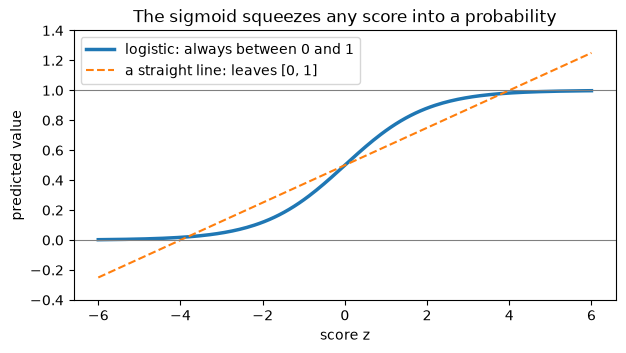

In [11]:
z = np.linspace(-6, 6, 200)
plt.figure(figsize=(7, 3.5))
plt.plot(z, sigmoid(z), lw=2.5, label="logistic: always between 0 and 1")
plt.plot(z, 0.5 + z / 8, ls="--", label="a straight line: leaves [0, 1]")
plt.axhline(0, color="grey", lw=0.8)
plt.axhline(1, color="grey", lw=0.8)
plt.ylim(-0.4, 1.4)
plt.title("The sigmoid squeezes any score into a probability")
plt.xlabel("score z")
plt.ylabel("predicted value")
plt.legend()
plt.show()

## <span class="hz-step-n">05</span> Training the logistic regression

In scikit-learn the model is `LogisticRegression`. We put a `StandardScaler` in front of it, inside a `Pipeline`. The scaler puts every feature on the same scale (mean 0, standard deviation 1), for two reasons:

1. the solver that fits the model converges faster and more reliably when tenure (months) and call minutes (hundreds) are not on wildly different scales;
2. later, the coefficients become comparable: each one says how much one standard deviation of that feature moves the score.

The pipeline learns the scaling from the training set only, then applies it to any data you give it.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("scale", StandardScaler()),
    ("logit", LogisticRegression(max_iter=2000)),
])
model.fit(X_train, y_train)
print("Trained on", len(X_train), "customers")

Trained on 3738 customers


`predict_proba` returns two columns per customer: the probability of class 0 (stays) and of class 1 (leaves). We keep the second one. Here are six test customers with their probability of leaving.

In [13]:
p_test = model.predict_proba(X_test)[:, 1]

show = df.loc[X_test.index, ["customer_id", "contract", "tenure_months", "support_tickets", "region", "churned"]].copy()
show["p_churn"] = p_test.round(2)
show.sample(6, random_state=42).sort_values("p_churn", ascending=False)

,customer_id,contract,tenure_months,support_tickets,region,churned,p_churn
1372,CM-10824,Month-to-month,1,1,Sur,0,0.56
2473,CM-12797,Month-to-month,13,3,Metropolitana,1,0.47
4126,CM-11834,Month-to-month,43,1,Centro,1,0.12
4073,CM-14545,Month-to-month,76,0,Sur,0,0.08
956,CM-11709,24 months,14,0,Metropolitana,0,0.05
3353,CM-14086,12 months,56,0,Metropolitana,0,0.03


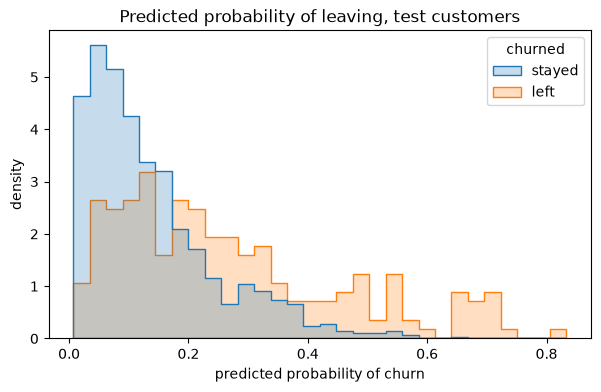

In [14]:
plt.figure(figsize=(7, 4))
sns.histplot(x=p_test, hue=y_test.map({0: "stayed", 1: "left"}), hue_order=["stayed", "left"],
             palette={"stayed": "tab:blue", "left": "tab:orange"}, bins=30, stat="density", common_norm=False, element="step")
plt.title("Predicted probability of leaving, test customers")
plt.xlabel("predicted probability of churn")
plt.ylabel("density")
plt.show()

The customers who really left (orange) tend to get higher probabilities, but the two groups overlap a lot. No single cut-off will separate them perfectly. That overlap is why the next two sections exist.

## <span class="hz-step-n">06</span> The confusion matrix

To turn probabilities into a decision we need a **threshold**: call the customer if $p \geq$ threshold. The default of `model.predict()` is 0.5. Each test customer then lands in one of four cells:

- **True positive (TP):** we call, and they were leaving. Money well spent.
- **False positive (FP):** we call, but they would have stayed. A wasted offer.
- **False negative (FN):** we don't call, and they leave. A lost customer.
- **True negative (TN):** we don't call, and they stay. Nothing happens.

In [15]:
from sklearn.metrics import confusion_matrix

pred_05 = model.predict(X_test)                       # threshold 0.5
tn, fp, fn, tp = confusion_matrix(y_test, pred_05).ravel()
print(f"True positives  (called, were leaving):   {tp}")
print(f"False positives (called, would stay):     {fp}")
print(f"False negatives (not called, left):       {fn}")
print(f"True negatives  (not called, stayed):     {tn}")

True positives  (called, were leaving):   30
False positives (called, would stay):     10
False negatives (not called, left):       175
True negatives  (not called, stayed):     1032


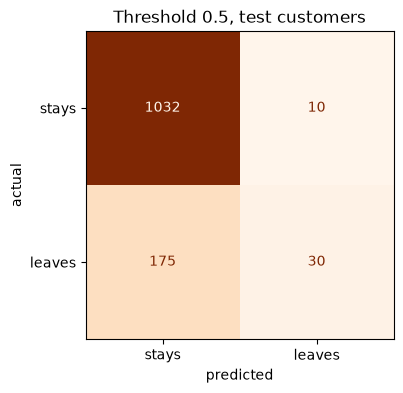

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_05, display_labels=["stays", "leaves"], cmap="Oranges", colorbar=False, ax=ax
)
ax.set_title("Threshold 0.5, test customers")
ax.set_xlabel("predicted")
ax.set_ylabel("actual")
plt.show()

Each metric reads the matrix from a different angle:

- **Precision** = TP / (TP + FP): of the customers we call, how many were really leaving? *How well do we spend the offers?*
- **Recall** = TP / (TP + FN): of the customers who leave, how many do we call? *How many leavers do we reach?*
- **F1**: a single number that balances the two (their harmonic mean).
- **AUC**: forget the threshold. Pick a random leaver and a random stayer: how often does the model give the leaver the higher probability? 0.5 is a coin flip, 1.0 is perfect. Session 5 draws the curve behind it.

In [17]:
from sklearn.metrics import precision_score, f1_score, roc_auc_score

print(f"Accuracy:  {accuracy_score(y_test, pred_05):.1%}   (the lazy model: {1 - y_test.mean():.1%})")
print(f"Precision: {precision_score(y_test, pred_05):.2f}")
print(f"Recall:    {recall_score(y_test, pred_05):.2f}")
print(f"F1:        {f1_score(y_test, pred_05):.2f}")
print(f"AUC:       {roc_auc_score(y_test, p_test):.2f}")

Accuracy:  85.2%   (the lazy model: 83.6%)
Precision: 0.75
Recall:    0.15
F1:        0.24
AUC:       0.72


In [18]:
from sklearn.metrics import classification_report

print(classification_report(y_test, pred_05, target_names=["stays", "leaves"]))

              precision    recall  f1-score   support

       stays       0.86      0.99      0.92      1042
      leaves       0.75      0.15      0.24       205

    accuracy                           0.85      1247
   macro avg       0.80      0.57      0.58      1247
weighted avg       0.84      0.85      0.81      1247



Read it like the retention manager would. When we call someone, we are right 3 times out of 4 (precision 0.75). But we only call 40 customers and reach **30 of the 205 leavers** (recall 0.15). Accuracy (85.2%) barely beats the lazy model, yet the AUC of 0.72 says the ranking carries real signal. The problem is not the model; it is the threshold.

The explainer below uses a toy example (customers buying a travel package), but the mechanism is identical: moving the threshold never changes the model, it moves customers between the cells of the matrix.

<div class="hz-widget" data-widget="threshold">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_4_Churn/">open this class on the course website</a> to use it.</p>
</div>

In [19]:
for t in [0.5, 0.3, 0.2]:
    pred_t = (p_test >= t).astype(int)
    print(f"threshold {t:.1f}: calls {pred_t.sum():4d}   "
          f"precision {precision_score(y_test, pred_t):.2f}   recall {recall_score(y_test, pred_t):.2f}")

threshold 0.5: calls   40   precision 0.75   recall 0.15
threshold 0.3: calls  180   precision 0.39   recall 0.34
threshold 0.2: calls  341   precision 0.33   recall 0.55


<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "The retention team lowers the threshold from 0.5 to 0.2. What happens?", "options": ["Recall goes up and precision goes down: more leavers reached, more offers wasted", "Both precision and recall go up, because the model gets better", "Nothing changes: the threshold is part of the trained model"], "answer": 0, "why": "A lower bar means more customers get called. More of the leavers are among them (recall up), but so are more stayers (precision down). The model itself is untouched.", "code": false}</script>
</div>

## <span class="hz-step-n">07</span> Choosing the threshold with money, not habit

0.5 is a habit, not a decision. The right threshold depends on what each mistake costs Cordillera. Finance gives us two numbers:

- a **missed churner** (false negative) costs about **USD 300** in lost margin;
- every **offer** costs about **USD 40**, whether the customer was leaving or not. On a stayer it is simply wasted.

We assume the offer keeps the leavers we call (optimistic, but a fine start). Then the total cost of a calling list is

$$\text{cost} = 40 \times \text{customers called} + 300 \times \text{churners not called}.$$

In the explainer, the curve is that cost for every threshold, computed on our 1,247 test customers. Change the two costs and watch the cheapest threshold move.

<div class="hz-widget" data-widget="cost-threshold">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_4_Churn/">open this class on the course website</a> to use it.</p>
</div>

In [20]:
COST_MISS = 300    # USD lost when a churner leaves without a call
COST_OFFER = 40    # USD per call with an offer

def total_cost(threshold):
    called = p_test >= threshold
    missed = (~called) & (y_test.values == 1)
    return COST_OFFER * called.sum() + COST_MISS * missed.sum()

print(f"Call nobody:        USD {COST_MISS * y_test.sum():,}")
print(f"Call everyone:      USD {COST_OFFER * len(y_test):,}")
print(f"Threshold 0.5:      USD {total_cost(0.5):,}")

Call nobody:        USD 61,500
Call everyone:      USD 49,880
Threshold 0.5:      USD 54,100


In [21]:
thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)
costs = pd.DataFrame({
    "threshold": thresholds,
    "calls": [(p_test >= t).sum() for t in thresholds],
    "cost_usd": [total_cost(t) for t in thresholds],
})
costs[costs["threshold"].isin([0.05, 0.10, 0.13, 0.15, 0.20, 0.30, 0.50, 0.70, 0.90])]

,threshold,calls,cost_usd
0,0.05,1009,44860
5,0.10,718,41020
8,0.13,575,39800
10,0.15,499,40660
15,0.20,341,41240
25,0.30,180,47700
45,0.50,40,54100
65,0.70,7,59680
85,0.90,0,61500


In [22]:
best = costs.loc[costs["cost_usd"].idxmin()]
print(f"Cheapest threshold: {best['threshold']:.2f}")
print(f"  calls {int(best['calls'])} customers, total cost USD {int(best['cost_usd']):,}")
print(f"  versus threshold 0.5: USD {total_cost(0.5) - best['cost_usd']:,.0f} cheaper")

Cheapest threshold: 0.13
  calls 575 customers, total cost USD 39,800
  versus threshold 0.5: USD 14,300 cheaper


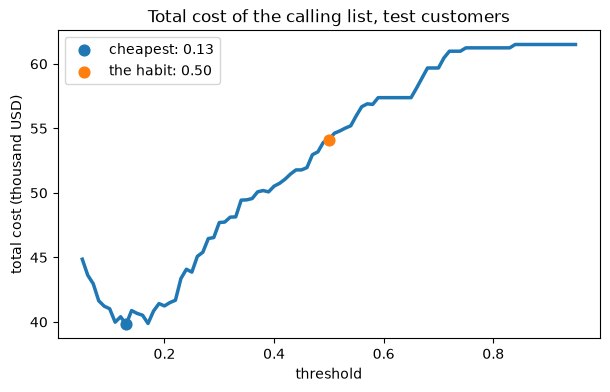

In [23]:
plt.figure(figsize=(7, 4))
plt.plot(costs["threshold"], costs["cost_usd"] / 1000, lw=2.5)
plt.scatter([best["threshold"]], [best["cost_usd"] / 1000], s=60, zorder=3, label=f"cheapest: {best['threshold']:.2f}")
plt.scatter([0.5], [total_cost(0.5) / 1000], s=60, zorder=3, label="the habit: 0.50")
plt.title("Total cost of the calling list, test customers")
plt.xlabel("threshold")
plt.ylabel("total cost (thousand USD)")
plt.legend()
plt.show()

The cheapest threshold is **0.13**: call 575 customers for a total of USD 39,800, against USD 54,100 at 0.5. And 0.13 is no coincidence. Calling a customer with probability $p$ costs 40; not calling costs, on average, $300 \times p$. Calling pays off as soon as $300p > 40$, that is $p > 40/300 \approx 0.13$. **The break-even threshold is the ratio of the two costs.**

One honest caveat: we picked the threshold on the test set. In a real project you would choose it on a validation set (or with cross-validation) and keep the test set for the final, untouched check.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "Finance revises the numbers: the offer now costs USD 100 instead of 40, and a lost churner still costs 300. Where does the best threshold move?", "options": ["Down, to call more customers", "Up, to about 0.33: each call must be more certain to be worth it", "It stays at 0.13, because the model has not changed"], "answer": 1, "why": "Calling pays off when 300 × p is larger than the offer cost, so the break-even moves to 100 / 300 ≈ 0.33 (in the explainer, the cheapest list on our test customers lands at 0.39, close to it). Dearer offers mean a shorter, surer calling list.", "code": false}</script>
</div>

## <span class="hz-step-n">08</span> What drives churn

The retention team will ask *why*. Because we scaled the features, the coefficients are comparable: each one says how much a one-standard-deviation change in that feature pushes the score (and so the probability) of leaving. Positive pushes towards leaving, negative towards staying. The dummies compare against the baseline: a Prepaid customer on a month-to-month contract in the Centro region, paying by bank transfer.

In [24]:
coefs = pd.Series(model.named_steps["logit"].coef_[0], index=X.columns).sort_values()
print(coefs.round(2).to_string())

contract_12 months           -0.60
contract_24 months           -0.51
plan_Unlimited               -0.48
tenure_months                -0.35
autopay                      -0.31
plan_Plus                    -0.07
age                          -0.05
plan_Basic                   -0.04
payment_method_Cash          -0.03
call_minutes                  0.01
payment_method_Unknown        0.02
intl_roaming                  0.06
payment_method_Debit card     0.08
payment_method_Credit card    0.08
data_gb                       0.09
region_Sur                    0.12
region_Metropolitana          0.19
region_Norte                  0.37
support_tickets               0.40
monthly_bill                  0.40


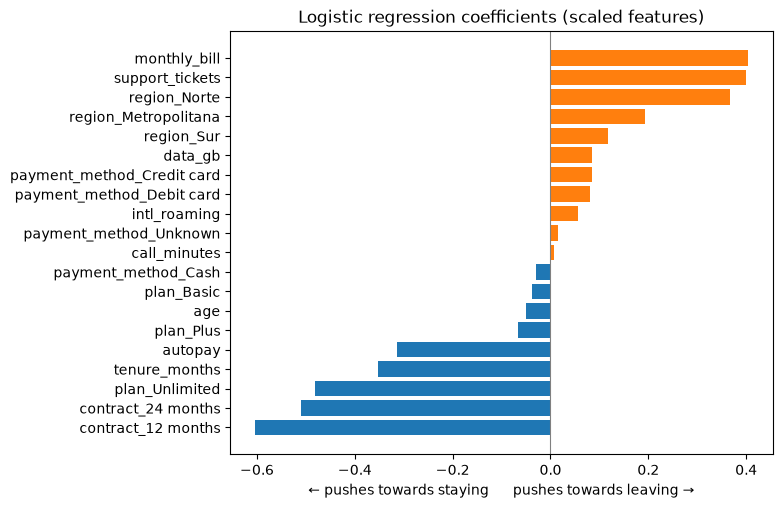

In [25]:
plt.figure(figsize=(7, 5.5))
colors = ["tab:blue" if c < 0 else "tab:orange" for c in coefs]
plt.barh(coefs.index, coefs.values, color=colors)
plt.axvline(0, color="grey", lw=0.8)
plt.title("Logistic regression coefficients (scaled features)")
plt.xlabel("← pushes towards staying      pushes towards leaving →")
plt.show()

Reading it carefully:

- **Contracts protect.** A 12- or 24-month contract has the strongest negative coefficients: those customers leave much less than month-to-month ones.
- **Complaints and bills push out.** More `support_tickets` and a higher `monthly_bill` raise the risk, and so does living in the **Norte** region.
- **Loyalty and autopay protect.** Longer `tenure_months`, `autopay` and an Unlimited plan go with staying.
- Age, call minutes and payment method barely matter.

These are **associations, not causes**. The model says customers on contracts leave less; it does not prove that signing someone onto a contract will keep them. Still, it tells the team where to look.

In [26]:
# Checking two stories against the raw churn rates
print(df.groupby("contract")["churned"].mean().map("{:.1%}".format).to_string())
print()
norte = df["region"] == "Norte"
many_tickets = df["support_tickets"] >= 2
print(f"Norte, 2+ tickets:        {df.loc[norte & many_tickets, 'churned'].mean():.1%}")
print(f"Everyone else:            {df.loc[~(norte & many_tickets), 'churned'].mean():.1%}")
print(f"New customers (< 6 months): {df.loc[df['tenure_months'] < 6, 'churned'].mean():.1%}")

contract
12 months          8.9%
24 months          7.8%
Month-to-month    22.0%

Norte, 2+ tickets:        51.1%
Everyone else:            14.1%
New customers (< 6 months): 44.4%


The raw rates back it up, and they suggest three concrete actions:

1. **Offer contracts** to month-to-month customers, the group with the highest churn.
2. **Fix support in the north**: Norte customers with two or more complaints leave far more than anyone else. That is a coverage and service problem, not a pricing one.
3. **Look after new customers**: in their first six months they leave at a much higher rate, so onboarding matters.

Notice that some of these patterns are thresholds ("2 or more tickets", "under 6 months") that a single straight score handles only roughly. Keep that in mind for session 5.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "The coefficient of <code>autopay</code> is negative. Which statement can you defend in front of the retention team?", "options": ["Turning on autopay for a customer will make them stay", "Customers with autopay tend to leave less, other things equal; it is worth testing whether promoting autopay helps", "Autopay is the most important reason customers stay"], "answer": 1, "why": "A coefficient shows an association in historical data, not a cause. And with contracts and Unlimited further from zero, autopay is not the strongest factor either. The honest move is to test it.", "code": false}</script>
</div>

## <span class="hz-step-n">09</span> What we tell the retention team

Let's put the options side by side, on the 1,247 test customers the model never saw.

In [27]:
def strategy(name, called):
    called = np.asarray(called, dtype=bool)
    reached = (called & (y_test.values == 1)).sum()
    cost = COST_OFFER * called.sum() + COST_MISS * (y_test.sum() - reached)
    return {"strategy": name, "calls": called.sum(), "churners reached": reached, "cost_usd": cost}

t_best = best["threshold"]
plan = pd.DataFrame([
    strategy("Call nobody", np.zeros(len(y_test))),
    strategy("Call everyone", np.ones(len(y_test))),
    strategy("Model, threshold 0.50", p_test >= 0.5),
    strategy(f"Model, threshold {t_best:.2f}", p_test >= t_best),
])
plan["saved vs nobody"] = plan["cost_usd"].iloc[0] - plan["cost_usd"]
plan

,strategy,calls,churners reached,cost_usd,saved vs nobody
0,Call nobody,0,0,61500,0
1,Call everyone,1247,205,49880,11620
2,"Model, threshold 0.50",40,30,54100,7400
3,"Model, threshold 0.13",575,149,39800,21700


Calling nobody costs USD 61,500 in lost customers. Calling everyone costs USD 49,880. The model at 0.5 is cheaper than nobody but worse than everyone, because it calls too few. The model at **0.13** calls 575 customers (46% of the base), reaches 149 of the 205 leavers and costs USD 39,800: **USD 21,700 less than doing nothing** and about USD 10,000 less than calling everyone.

**The message, top of the pyramid:** *Call every customer whose predicted churn risk is above 13%, starting with month-to-month customers and the north; on this sample that saves about USD 21,700 compared with doing nothing.*

Then the supporting points: who is on the list (the coefficients), how sure we are (AUC 0.72, recall at 0.13), and what we assumed (the costs and that the offer works).

## <span class="hz-step-n">10</span> Your project this week

Today we went from "how accurate is it?" to "what does each error cost?". That is exactly [Advance 4 · The right metric](https://hizocar.github.io/usm-course-intensivo/project/progress/#advance-4-the-right-metric), due Tuesday at 23:59.

- **Case B (FinTrust Bank)** does what we did today, with `default` instead of `churned`: a stratified split, a logistic regression, the confusion matrix, precision, recall, F1 and AUC on the test set. Then choose a threshold with the cost of each error: approving a customer who defaults (you lose the loan) versus rejecting a good customer (you lose the interest you would have earned). Write down the two costs you assume and why.
- **Case A (TalentCo)** stays in regression, where the "right metric" question looks like this: 5-fold cross-validation of your linear regression, at least two coefficients interpreted in business terms (like our contract and support stories), and a justified choice between MAE and RMSE. RMSE punishes big misses more; is a big error on a salary worse than several small ones?
- **Case C** follows A or B depending on your target.
- **Everyone:** a table with the metrics so far (you will extend it in the final submission), and the key message of your presentation in **one sentence**, like our "call everyone above 13%".

**Next session:** our logistic regression draws one smooth score, but churn hides thresholds such as "two or more tickets in the north". Can a decision tree, or a forest of them, do better? And how do we tell the story to the people who decide?